In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

asean = pd.read_csv("asean_olympics_clean.csv")
official_medals = pd.read_csv("asean_official_medals.csv")

print("Athlete-event dataset:", asean.shape)
print("Official medal dataset:", official_medals.shape)

Athlete-event dataset: (3233, 23)
Official medal dataset: (90, 23)


In [2]:
print("Countries:", asean["region"].nunique())
print("Unique athletes:", asean["ID"].nunique())
print("Year range:", asean["Year"].min(), "to", asean["Year"].max())
print("Sports:", asean["Sport"].nunique())
print("Duplicate rows:", asean.duplicated().sum())

Countries: 10
Unique athletes: 1964
Year range: 1924 to 2016
Sports: 31
Duplicate rows: 0


In [3]:
asean["Official_Medal_Flag"] = 0

medal_rows = asean["Medal"].notna()

first_medal_record = ~asean.loc[
    medal_rows
].duplicated(
    subset=["Games", "NOC", "Event", "Medal"]
)

asean.loc[
    asean.loc[medal_rows].index[first_medal_record],
    "Official_Medal_Flag"
] = 1

print(asean["Official_Medal_Flag"].value_counts())
print("Official medals:", asean["Official_Medal_Flag"].sum())

Official_Medal_Flag
0    3143
1      90
Name: count, dtype: int64
Official medals: 90


In [4]:
asean["Age_Group"] = pd.cut(
    asean["Age"],
    bins=[0, 17, 24, 29, 34, 100],
    labels=[
        "Under 18",
        "18–24",
        "25–29",
        "30–34",
        "35 and above"
    ]
)

asean["Age_Group"] = (
    asean["Age_Group"]
    .astype("object")
    .fillna("Unknown")
)

In [5]:
asean["Decade"] = (
    asean["Year"] // 10 * 10
).astype(str) + "s"

In [6]:
display(
    asean[
        [
            "Name", "Year", "Decade",
            "Age", "Age_Group",
            "Medal_Status",
            "Official_Medal_Flag"
        ]
    ].head()
)

,Name,Year,Decade,Age,Age_Group,Medal_Status,Official_Medal_Flag
0,Zulkifli Abbas,1984,1980s,28.0,25–29,No Medal,0
1,Maizurah Abdul Rahim,2016,2010s,17.0,Under 18,No Medal,0
2,Chairil Anwar Abdul Aziz,1996,1990s,24.0,18–24,No Medal,0
3,Chairil Anwar Abdul Aziz,2000,2000s,28.0,25–29,No Medal,0
4,Mohamed Abdul Hadj,1992,1990s,25.0,25–29,No Medal,0


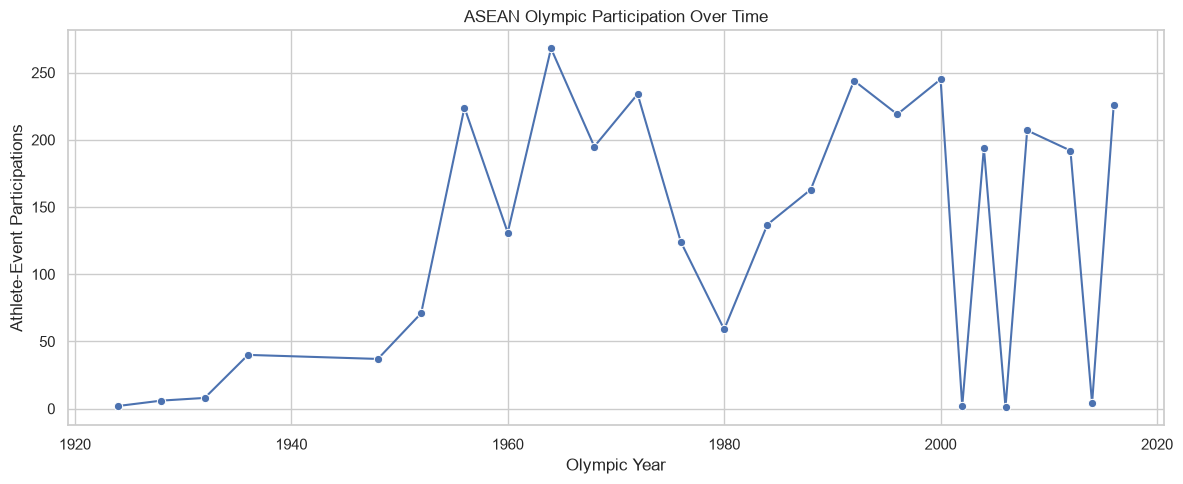

In [7]:
participation_trend = (
    asean.groupby("Year")
    .size()
    .reset_index(name="Participations")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=participation_trend,
    x="Year",
    y="Participations",
    marker="o"
)

plt.title("ASEAN Olympic Participation Over Time")
plt.xlabel("Olympic Year")
plt.ylabel("Athlete-Event Participations")
plt.tight_layout()
plt.show()

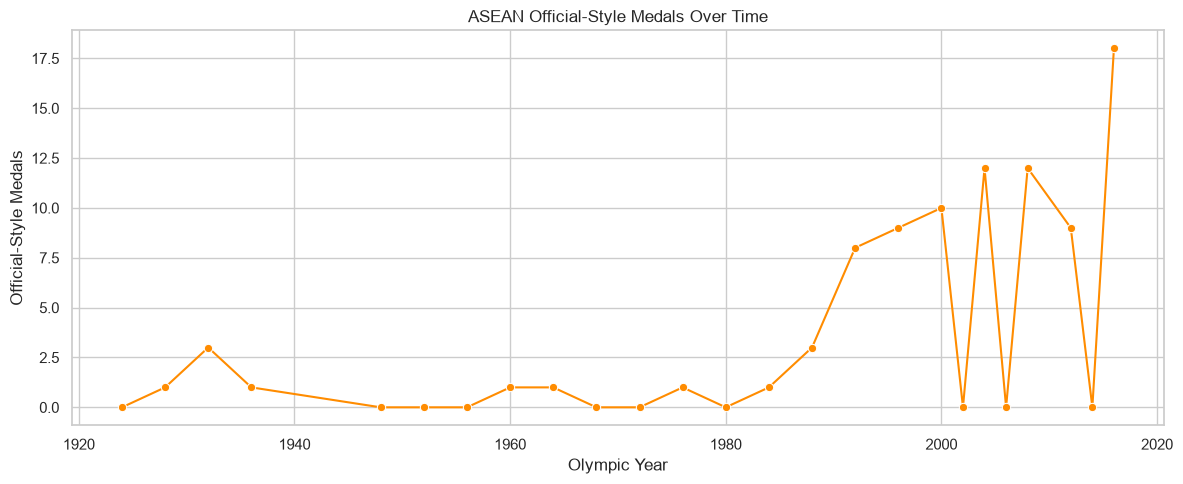

In [8]:
medal_trend = (
    asean.groupby("Year")["Official_Medal_Flag"]
    .sum()
    .reset_index(name="Official_Medals")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=medal_trend,
    x="Year",
    y="Official_Medals",
    marker="o",
    color="darkorange"
)

plt.title("ASEAN Official-Style Medals Over Time")
plt.xlabel("Olympic Year")
plt.ylabel("Official-Style Medals")
plt.tight_layout()
plt.show()

In [9]:
# Create the country KPI table

country_kpis = (
    asean.groupby("region")
    .agg(
        Participations=("ID", "size"),
        Unique_Athletes=("ID", "nunique"),
        Medalist_Records=("Won_Medal", "sum"),
        Official_Medals=("Official_Medal_Flag", "sum"),
        Female_Participations=(
            "Gender",
            lambda x: (x == "Female").sum()
        )
    )
    .reset_index()
)

country_kpis["Medalist_Record_Rate"] = (
    country_kpis["Medalist_Records"]
    / country_kpis["Participations"]
    * 100
).round(2)

country_kpis["Female_Participation_Percentage"] = (
    country_kpis["Female_Participations"]
    / country_kpis["Participations"]
    * 100
).round(2)

country_kpis = country_kpis.sort_values(
    "Official_Medals",
    ascending=False
)

display(country_kpis)

,region,Participations,Unique_Athletes,Medalist_Records,Official_Medals,Female_Participations,Medalist_Record_Rate,Female_Participation_Percentage
8,Thailand,747,462,30,30,214,4.02,28.65
2,Indonesia,412,275,41,30,136,9.95,33.01
4,Malaysia,577,340,16,11,102,2.77,17.68
6,Philippines,694,389,10,10,104,1.44,14.99
7,Singapore,349,172,9,5,129,2.58,36.96
9,Vietnam,216,143,4,4,76,1.85,35.19
1,Cambodia,63,45,0,0,17,0.00,26.98
0,Brunei,10,9,0,0,2,0.00,20.00
5,Myanmar,111,86,0,0,24,0.00,21.62
3,Laos,54,47,0,0,12,0.00,22.22


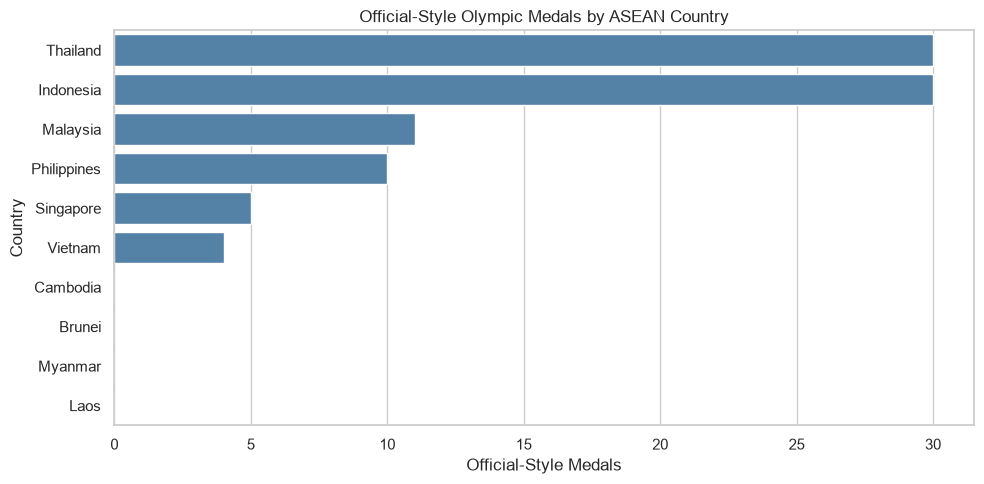

In [10]:
# Visualise official medals

plt.figure(figsize=(10, 5))

sns.barplot(
    data=country_kpis,
    x="Official_Medals",
    y="region",
    color="steelblue"
)

plt.title("Official-Style Olympic Medals by ASEAN Country")
plt.xlabel("Official-Style Medals")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [11]:
# Objective 3 — Identify medal-producing sports

sport_medals = (
    asean.groupby("Sport")["Official_Medal_Flag"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="Official_Medals")
)

display(sport_medals.head(10))

,Sport,Official_Medals
0,Badminton,27
1,Weightlifting,24
2,Boxing,19
3,Taekwondo,6
4,Swimming,3
5,Table Tennis,3
6,Athletics,2
7,Diving,2
8,Shooting,2
9,Archery,1


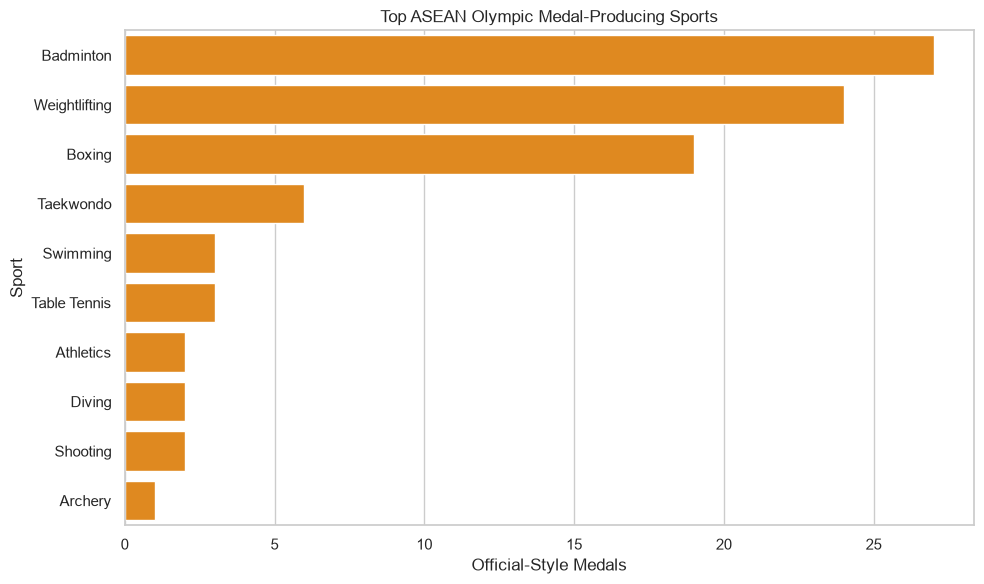

In [12]:
# Plot the top ten

top_sports = sport_medals.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_sports,
    x="Official_Medals",
    y="Sport",
    color="darkorange"
)

plt.title("Top ASEAN Olympic Medal-Producing Sports")
plt.xlabel("Official-Style Medals")
plt.ylabel("Sport")
plt.tight_layout()
plt.show()

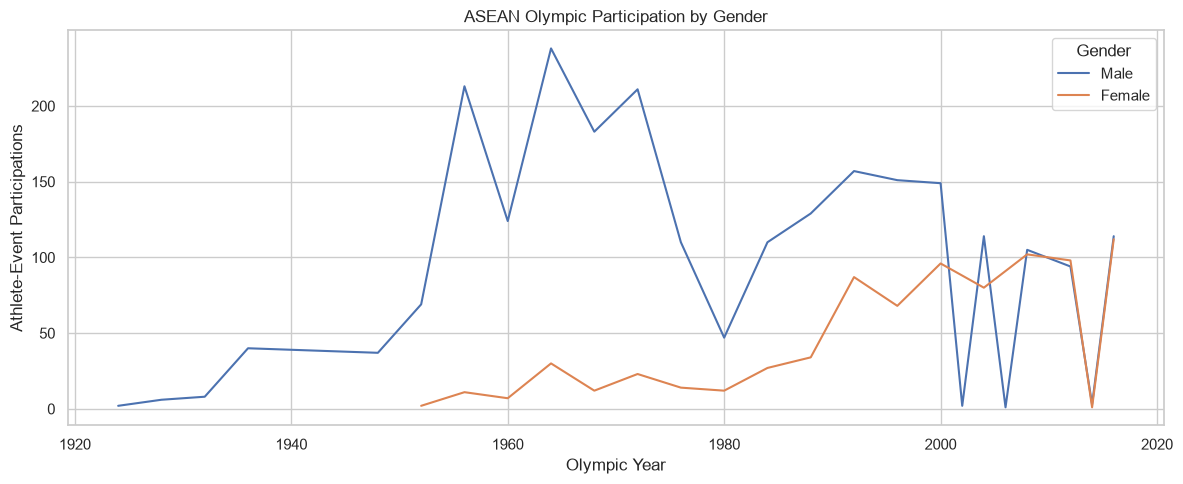

In [13]:
# Objective 4 — Analyse gender participation

gender_trend = (
    asean.groupby(["Year", "Gender"])
    .size()
    .reset_index(name="Participations")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=gender_trend,
    x="Year",
    y="Participations",
    hue="Gender"
)

plt.title("ASEAN Olympic Participation by Gender")
plt.xlabel("Olympic Year")
plt.ylabel("Athlete-Event Participations")
plt.tight_layout()
plt.show()

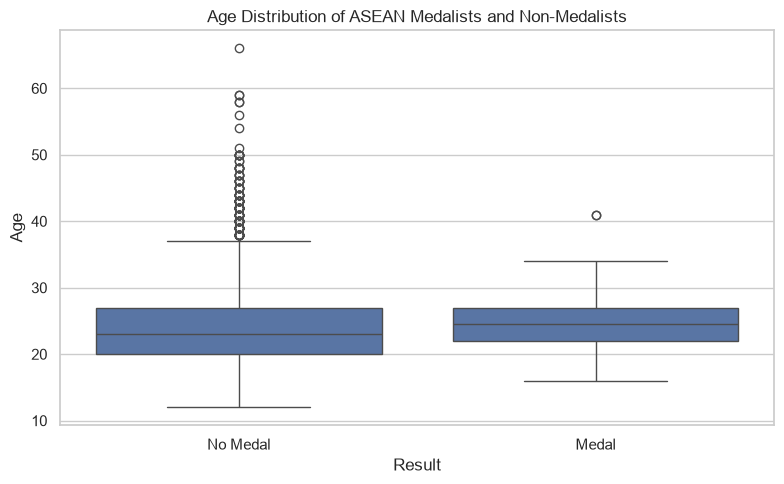

In [16]:
# Objective 5 — Compare athlete age profiles

age_data = asean.dropna(subset=["Age"]).copy()

age_data["Medal_Result"] = age_data["Won_Medal"].map({
    0: "No Medal",
    1: "Medal"
})

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=age_data,
    x="Medal_Result",
    y="Age"
)

plt.title("Age Distribution of ASEAN Medalists and Non-Medalists")
plt.xlabel("Result")
plt.ylabel("Age")
plt.tight_layout()

plt.savefig(
    "ASEAN_Age_Medal_Boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Preliminary Findings by Research Objective

| Objective | Analysis performed | Preliminary finding |
|---|---|---|
| 1. Participation and medal trends | Participation and medal line charts | To be completed after interpreting the charts |
| 2. Country benchmarking | Country KPI table and medal bar chart | To be completed |
| 3. Medal-producing sports | Top-sports analysis | To be completed |
| 4. Gender differences | Gender participation trend | To be completed |
| 5. Athlete profiles | Age box plot | To be completed |
| 6. Emerging or declining areas | Country-sport trend analysis | To be completed |
| 7. Medal opportunities | Participation and medal-conversion comparison | To be completed |

In [15]:
# Export the Day 3 dataset

asean.to_csv(
    "asean_olympics_powerbi.csv",
    index=False
)

country_kpis.to_csv(
    "asean_country_kpis.csv",
    index=False
)

print("Day 3 analysis datasets exported.")

Day 3 analysis datasets exported.
